# Onset-interval calibration

Compare native onset intervals with intervals adjusted by validation-event
log-residual offsets. Coverage is evaluated on observed events. The adjustment
leaves point predictions, native crossing CDFs and integrated Brier scores unchanged.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:06:57+00:00
Inputs: included aggregate tables and public external extracts


## Internal native and residual intervals

,model,method,coverage,mean_width_H
0,cox_ph,native,0.7687,439.1459
1,cox_ph,validation_log_asymmetric,0.8905,252.3011
3,dpi_evt,native,0.1973,304.5421
4,dpi_evt,validation_log_asymmetric,0.8803,514.3550
6,dpi_evt_A,native,0.1782,182.7710
7,dpi_evt_A,validation_log_asymmetric,0.8810,457.3891
17,gbm_distribution,native,0.8612,191.8482
18,gbm_distribution,validation_log_asymmetric,0.8762,138.8052
37,transformer_cummax,validation_log_asymmetric,0.8626,392.4352


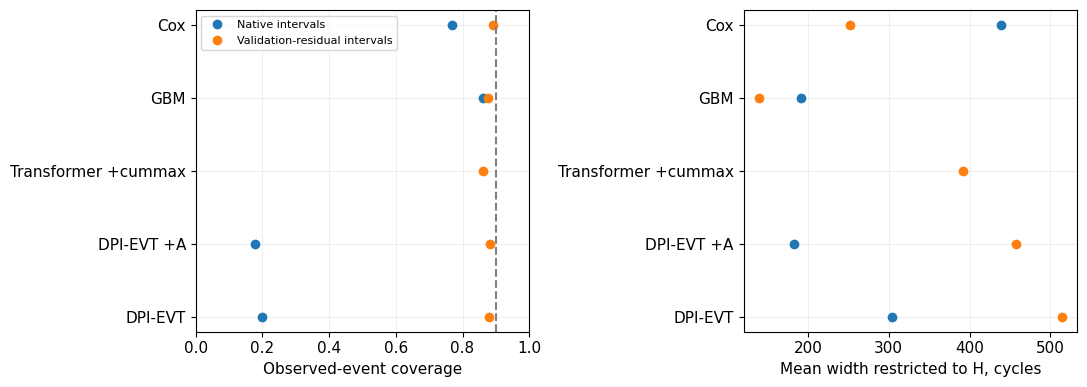

In [2]:
intervals=pd.read_csv(TABLES/"interval_internal.csv")
selected=["dpi_evt","dpi_evt_A","transformer_cummax","gbm_distribution","cox_ph"]
d=intervals[intervals.model.isin(selected) & np.isclose(intervals.target,.90)]
display(d[["model","method","coverage","mean_width_H"]].round(4))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for method,g in d.groupby("method"):
    g=g.set_index("model").reindex(selected)
    method_label={"native":"Native intervals", "validation_log_asymmetric":"Validation-residual intervals"}[method]
    axes[0].plot(g.coverage,np.arange(len(g)),"o",label=method_label)
    axes[1].plot(g.mean_width_H,np.arange(len(g)),"o",label=method_label)
labels=["DPI-EVT", "DPI-EVT +A", "Transformer +cummax", "GBM", "Cox"]
for ax in axes: ax.set_yticks(np.arange(len(selected)),labels)
axes[0].axvline(.9,color="grey",linestyle="--");axes[0].set(xlabel="Observed-event coverage",xlim=(0,1))
axes[1].set(xlabel="Mean width restricted to H, cycles")
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

## Matched controls and external transfer

In [3]:
controls=pd.read_csv(TABLES/"control_interval_summary.csv")
display(controls[controls.source.eq("internal") & np.isclose(controls.target,.9)][["label","coverage","mean_width_H"]].round(4))
external=pd.read_csv(TABLES/"interval_external.csv")
display(external[external.method.eq("validation_log_asymmetric") & np.isclose(external.target,.9)].pivot(index="model",columns="source",values="coverage").round(3))

,label,coverage,mean_width_H
10,DPI-EVT +A/no reciprocal drift,0.8878,403.4669
22,Threshold-projected Transformer/GBM,0.8762,138.8052
34,Time-warped Transformer/GBM,0.8762,138.6901
46,Transformer matched +A/crossing loss,0.8612,418.2289
58,Transformer matched +P/crossing loss,0.8707,340.1524
70,Transformer matched +P/head loss,0.8728,347.8425


source,Adapazari,Christchurch,KFS-TCUA,KFS-TCUI,LEAP-2017
model,,,,,
cox_ph,0.565,0.844,0.533,0.660,0.671
dpi_evt,0.730,0.822,0.667,0.723,0.824
dpi_evt_A,0.704,0.858,0.667,0.727,0.816
dpi_evt_AC,0.770,0.942,0.933,0.793,0.969
dpi_evt_C,0.745,0.867,0.800,0.717,0.918
evt_ssm,0.545,0.827,0.600,0.630,0.839
gbm_distribution,0.491,0.680,0.533,0.367,0.525
gp_prefix,0.206,0.213,0.867,0.753,0.420
loglinear_prefix,0.341,0.302,0.000,0.650,0.510


## Recompute with fitted local models

The calibrator uses the internal validation events of each fold. The same sites were used for checkpoint selection, so the reported coverage is empirical and conditional on observed events. It does not provide an independent split-conformal guarantee.

In [4]:
RECOMPUTE_INTERVALS = False
if RECOMPUTE_INTERVALS:
    from calibrate_intervals import ensure_onset_interval_evaluation
    print(ensure_onset_interval_evaluation(ROOT))
else:
    print("Interval summaries loaded. Set RECOMPUTE_INTERVALS=True to recompute with local models.")

Interval summaries loaded. Set RECOMPUTE_INTERVALS=True to recompute with local models.
